<center><img src="prog_lang.jpg" width=500></center>

Comment déterminer quels langages de programmation et quelles technologies sont les plus utilisés ? Quels langages gagnent ou perdent en popularité, afin de vous aider à orienter vos efforts ?

Une excellente source de données est Stack Overflow, un site de questions-réponses pour les programmeurs qui regroupe plus de 16 millions de questions sur des sujets liés à la programmation. Chaque question sur Stack Overflow est associée à un tag qui identifie son thème ou sa technologie. En comptant le nombre de questions liées à chaque technologie, vous pouvez estimer la popularité des différents langages de programmation.

Dans ce projet, vous utiliserez des données issues du Stack Exchange Data Explorer pour étudier la popularité relative de R par rapport à d’autres langages de programmation.

Vous travaillerez avec un jeu de données contenant une observation par tag et par année, comprenant le nombre de questions pour ce tag et le nombre total de questions cette année‑là.

`stack_overflow_data.csv`
|Column|Description|
|------|-----------|
|`year`|L’année où la question a été posée (2008-2020)|
|`tag`|Un mot ou une expression décrivant le sujet de la question, par exemple le langage de programmation|
|`num_questions`|Le nombre de questions portant un certain tag pour cette année|
|`year_total`|Le nombre total de questions posées cette année|

In [1]:
# Load necessary packages
library(readr)
library(dplyr)
library(ggplot2)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [2]:
# Load the dataset
data <- read_csv("stack_overflow_data.csv")

Rows: 420066 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): tag
dbl (3): year, num_questions, year_total

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
# View the dataset
head(data)

year,tag,num_questions,year_total
<dbl>,<chr>,<dbl>,<dbl>
2008,treeview,69,168541
2008,scheduled-tasks,30,168541
2008,specifications,21,168541
2008,rendering,35,168541
2008,http-post,6,168541
2008,static-assert,1,168541


year,tag,num_questions,year_total,percentage
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
2020,r,52662,5452545,0.9658242


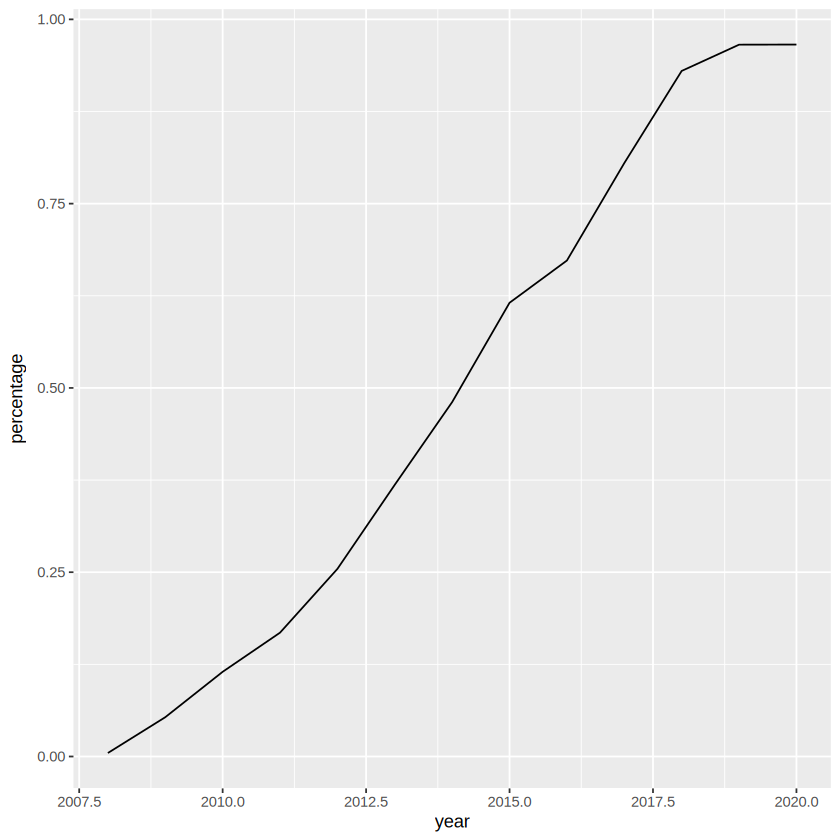

In [4]:
# 1. Calcul du pourcentage pour l'année 2020 (Tag "R")
r_over_r <- data %>%
  mutate(percentage = (num_questions / year_total) * 100) %>%
  filter(tag == "r")

# Visualisation
ggplot(r_over_r,aes(x=year,y=percentage))+geom_line()

r_2020 <- r_over_r %>%
  filter(year == 2020)

r_2020

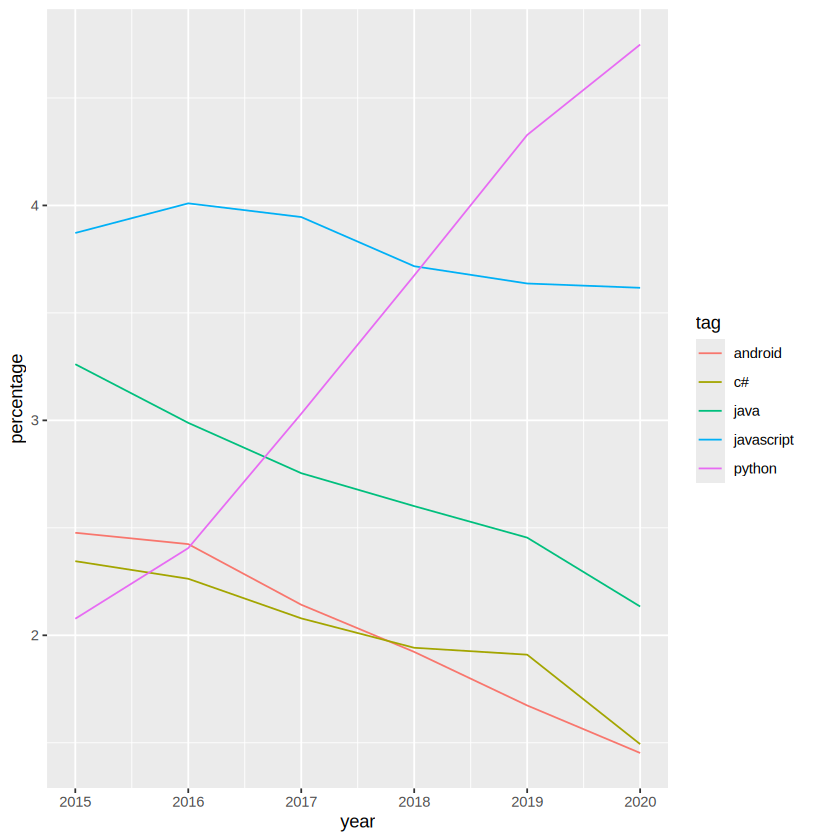

In [10]:
# 1. Avec pull(tag), highest_tags est déjà une liste simple
highest_tags <- data %>%
  filter(year >= 2015) %>%
  group_by(tag) %>%
  summarize(tag_total = sum(num_questions)) %>%
  arrange(desc(tag_total)) %>%
  pull(tag) %>%
  head(n = 5)

# 2. Utilise directement highest_tags (sans $tag)
data_subset <- data %>%
  mutate(percentage = (num_questions / year_total) * 100) %>%
  filter(tag %in% highest_tags, year >= 2015)

# 3. Affichage du graphique
ggplot(data_subset, aes(x = year, y = percentage, color = tag)) +
  geom_line()
